# Quiz 1：影像檢索（30 分）

**蘇芯儀 / Sharon0726**

本 Notebook 已執行並顯示 Colab T4 訓練保存的真實結果。訓練程式與推論程式完整附在同目錄；需要重訓請使用 `MMIP_Week5_Colab.ipynb`，本 Notebook 重跑只讀取結果，不重新訓練。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week5 with results/ present.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))
def source(name): display(Markdown('```python\n'+Path(name).read_text(encoding='utf-8')+'\n```'))


## 1. 準備資料集（5 分）

CIFAR-10：相同類別視為相關影像。官方 train 取每類 1000 訓練、200 驗證、1000 gallery，剩餘不使用；官方 test 全部作為 query。影像來源 ID 加上官方 split 才是唯一識別碼。影像為 224×224，只有訓練隨機水平翻轉。

In [2]:
display(read('retrieval_data.json'))
s=pd.read_csv(R/'retrieval_split.csv')
display(s.groupby(['split','label']).size().unstack())
assert not s.duplicated(['source','source_id']).any()
print('PASS: no image ID crosses partitions.')

{'dataset': 'uoft-cs/cifar10',
 'revision': '0b2714987fa478483af9968de7c934580d0bb9a2',
 'classes': ['airplane',
  'automobile',
  'bird',
  'cat',
  'deer',
  'dog',
  'frog',
  'horse',
  'ship',
  'truck'],
 'counts': {'train': 10000,
  'validation': 2000,
  'gallery': 10000,
  'query': 10000},
 'relevance': 'same CIFAR-10 class; semantic category retrieval, not instance identity',
 'gallery_relevant_per_class': 1000,
 'unused_official_train': 28000}

label,0,1,2,3,4,5,6,7,8,9
split,,,,,,,,,,
gallery,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
query,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
train,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
validation,200,200,200,200,200,200,200,200,200,200


PASS: no image ID crosses partitions.


## 2. CNN 與 ViT 模型訓練（基礎 10 分、進階 5 分）

ResNet18 / ViT-Tiny → 128 維 L2 normalized embedding。部分微調 layer4 / 最後 Transformer block，使用 supervised contrastive loss + 0.5 × 分類 cross-entropy。6 epochs，AdamW lr=0.0003，batch=64；以 validation leave-one-out Hit@1 選 checkpoint。下面是實際模型及損失程式。

```python
"""Retrieval metric learning and image/text fusion models."""
import torch
from torch import nn
from torch.nn import functional as F


def backbone(kind, pretrained=True):
    if kind == 'resnet':
        from torchvision.models import resnet18, ResNet18_Weights
        net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        dim = net.fc.in_features
        net.fc = nn.Identity()
    else:
        import timm
        net = timm.create_model('vit_tiny_patch16_224.augreg_in21k_ft_in1k',pretrained=pretrained,num_classes=0)
        dim = net.num_features
    return net, dim


class RetrievalModel(nn.Module):
    def __init__(self, kind, dimension=128, pretrained=True):
        super().__init__()
        self.kind = kind
        self.backbone, dim = backbone(kind, pretrained)
        prefixes = ('blocks.11.','norm.') if kind=='vit' else ('layer4.',)
        for name, p in self.backbone.named_parameters():
            p.requires_grad = name.startswith(prefixes)
        self.project = nn.Linear(dim, dimension)
        self.classifier = nn.Linear(dimension, 10)
    def forward(self, images):
        z = F.normalize(self.project(self.backbone(images)),dim=-1)
        return z, self.classifier(z)
    def training_mode(self):
        self.train()
        self.backbone.eval()
        if self.kind=='vit':
            self.backbone.blocks[-1].train(); self.backbone.norm.train()
        else:
            self.backbone.layer4.train()


def supervised_contrastive(z, labels, temperature=.1):
    """One-view supervised contrastive loss; self-pairs excluded from both sums."""
    n=len(z); diagonal=torch.eye(n,dtype=torch.bool,device=z.device)
    positives=labels[:,None].eq(labels[None,:]) & ~diagonal
    logits=(z.float() @ z.float().T)/temperature
    logits=logits.masked_fill(diagonal,-1e9)
    logp=logits-torch.logsumexp(logits,dim=1,keepdim=True)
    counts=positives.sum(1); valid=counts>0
    if not valid.any(): return z.sum()*0
    return -((logp*positives).sum(1)/counts.clamp_min(1))[valid].mean()



```

,model,best_epoch,trainable_parameters,backbone_max_abs_change,train_seconds
0,resnet,6,8460682,0.046070,159.687008
1,vit,4,471242,0.053578,155.286048


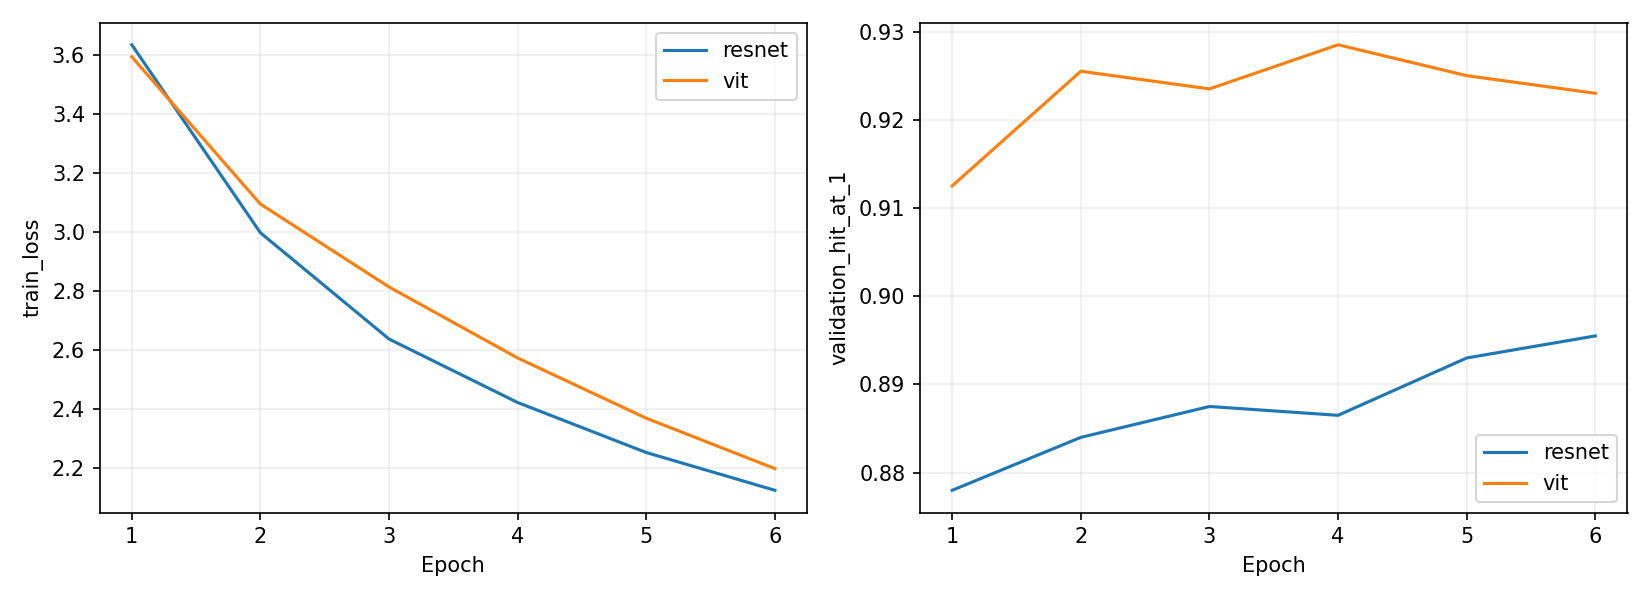

In [3]:
src=Path('models.py').read_text(encoding='utf-8')
display(Markdown('```python\n'+src[:src.index('class FusionModel')]+'\n```'))
display(pd.read_csv(R/'retrieval_metrics.csv')[['model','best_epoch','trainable_parameters','backbone_max_abs_change','train_seconds']])
show('retrieval_learning.png')

完整訓練／推論迴圈在 [quiz1_retrieval.py](quiz1_retrieval.py)。Colab 原始輸出保存在 `results/training.log`，可核對各 epoch。

## 3. 展示檢索推論（5 分）

每列為固定的前六張 test query 之一，以及 cosine similarity top-5 gallery 影像。綠字代表同類，紅字異類；沒有挑選成功例。

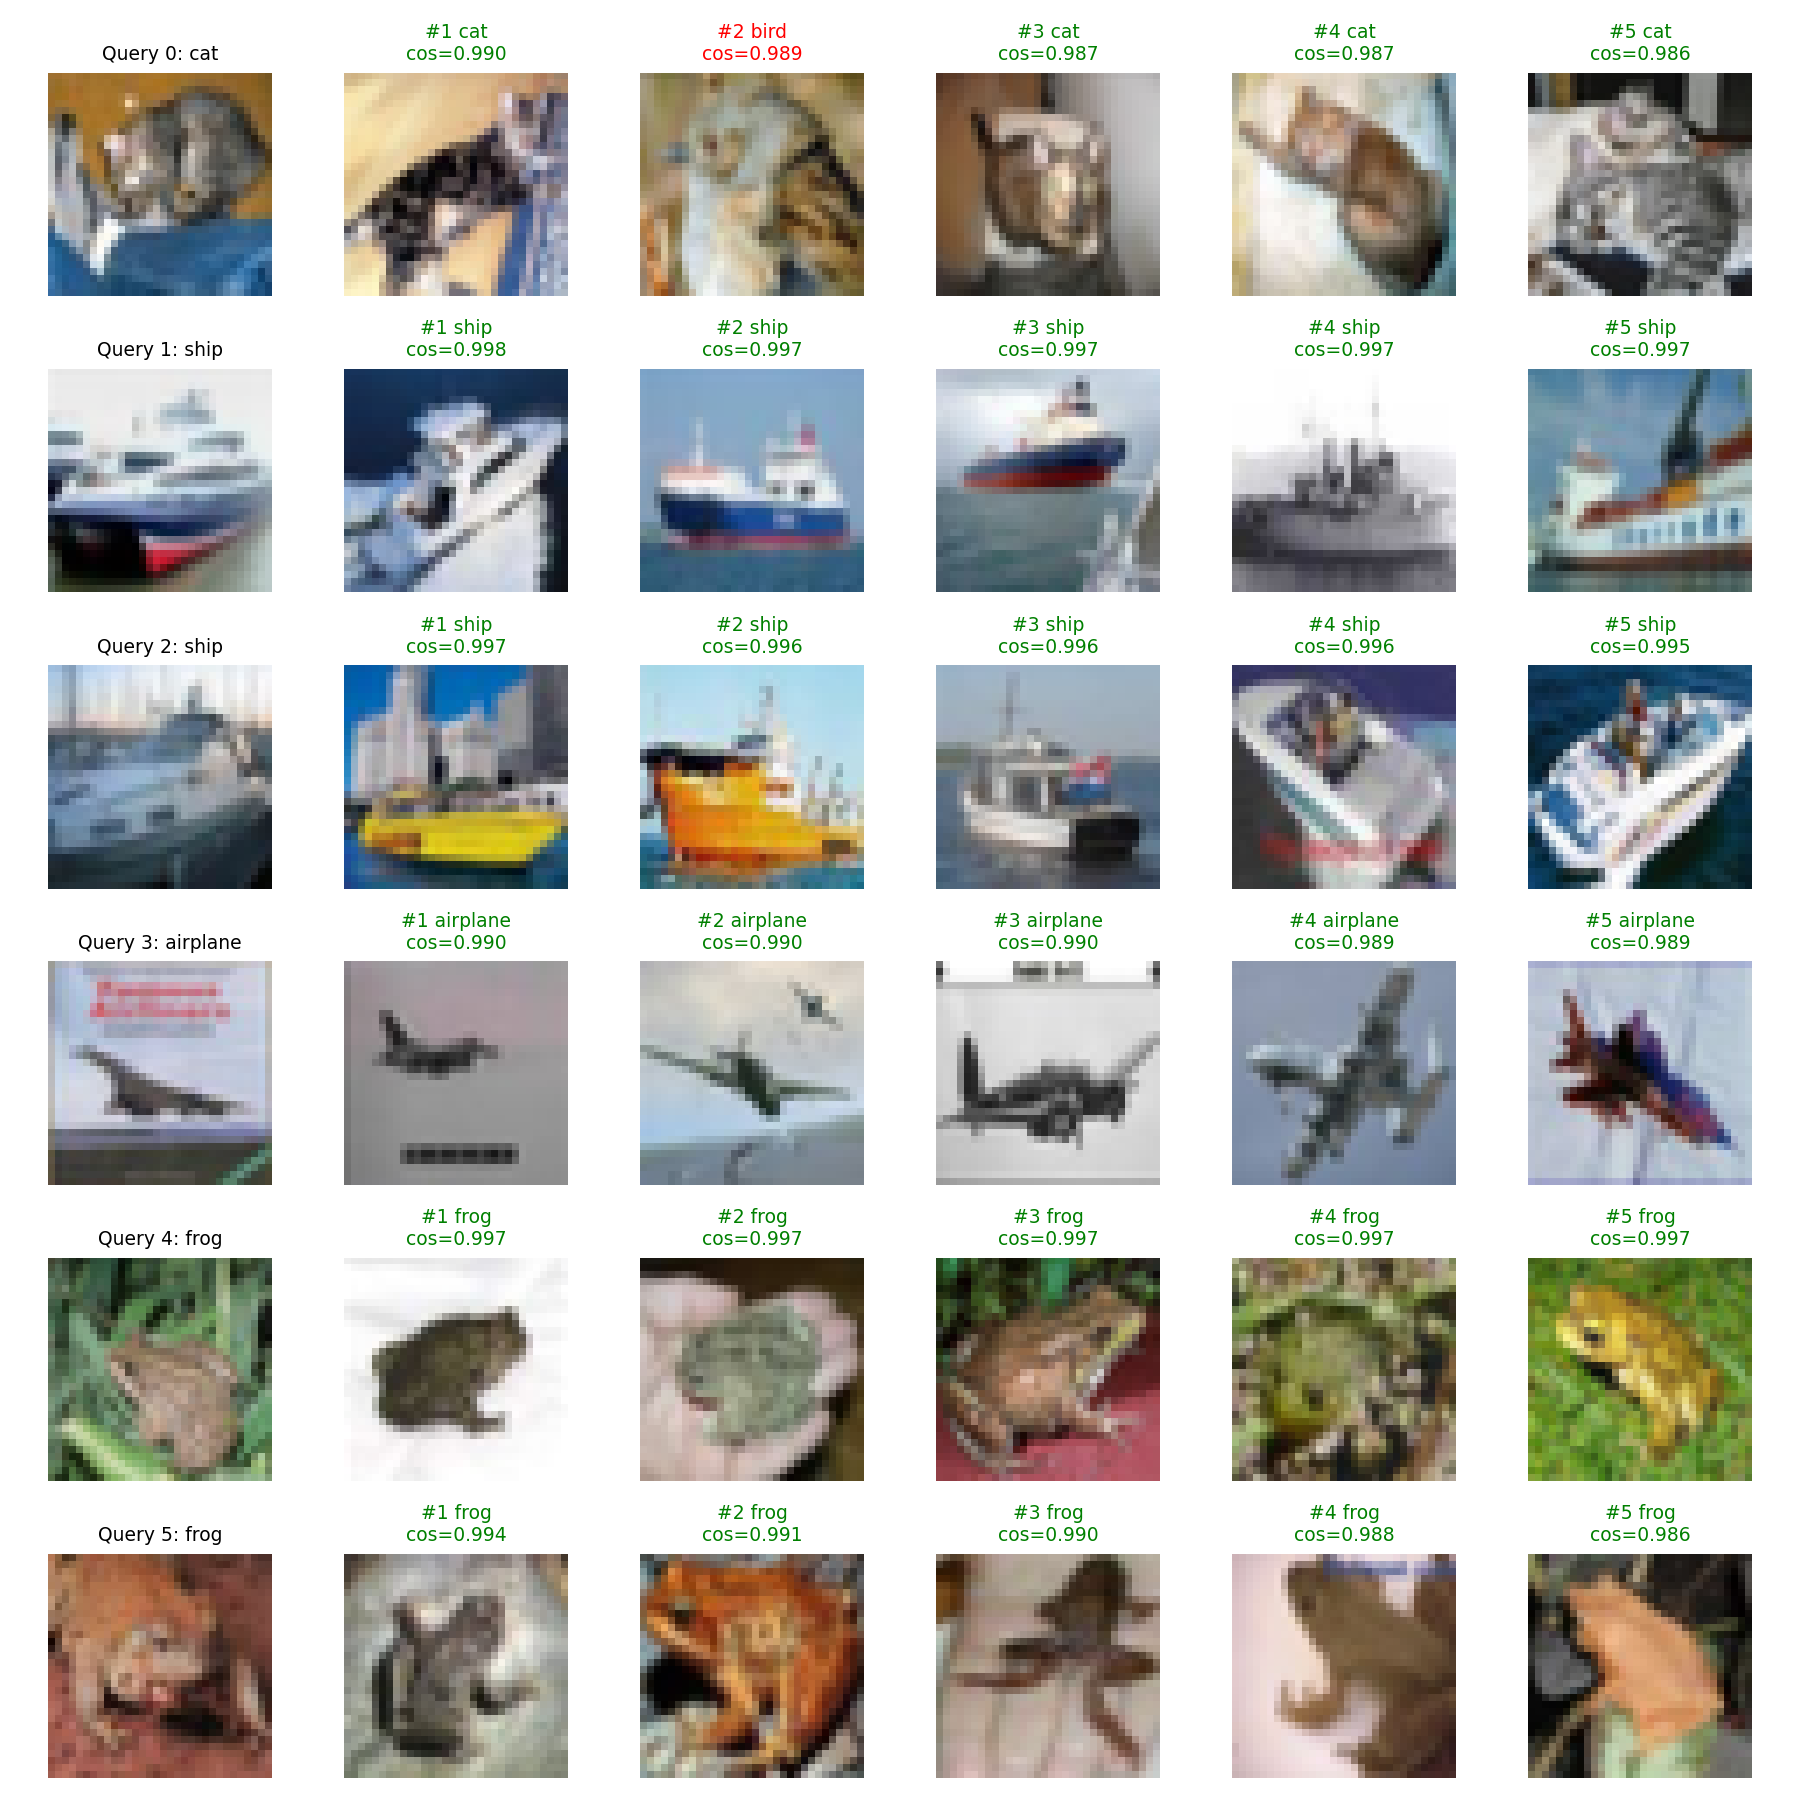

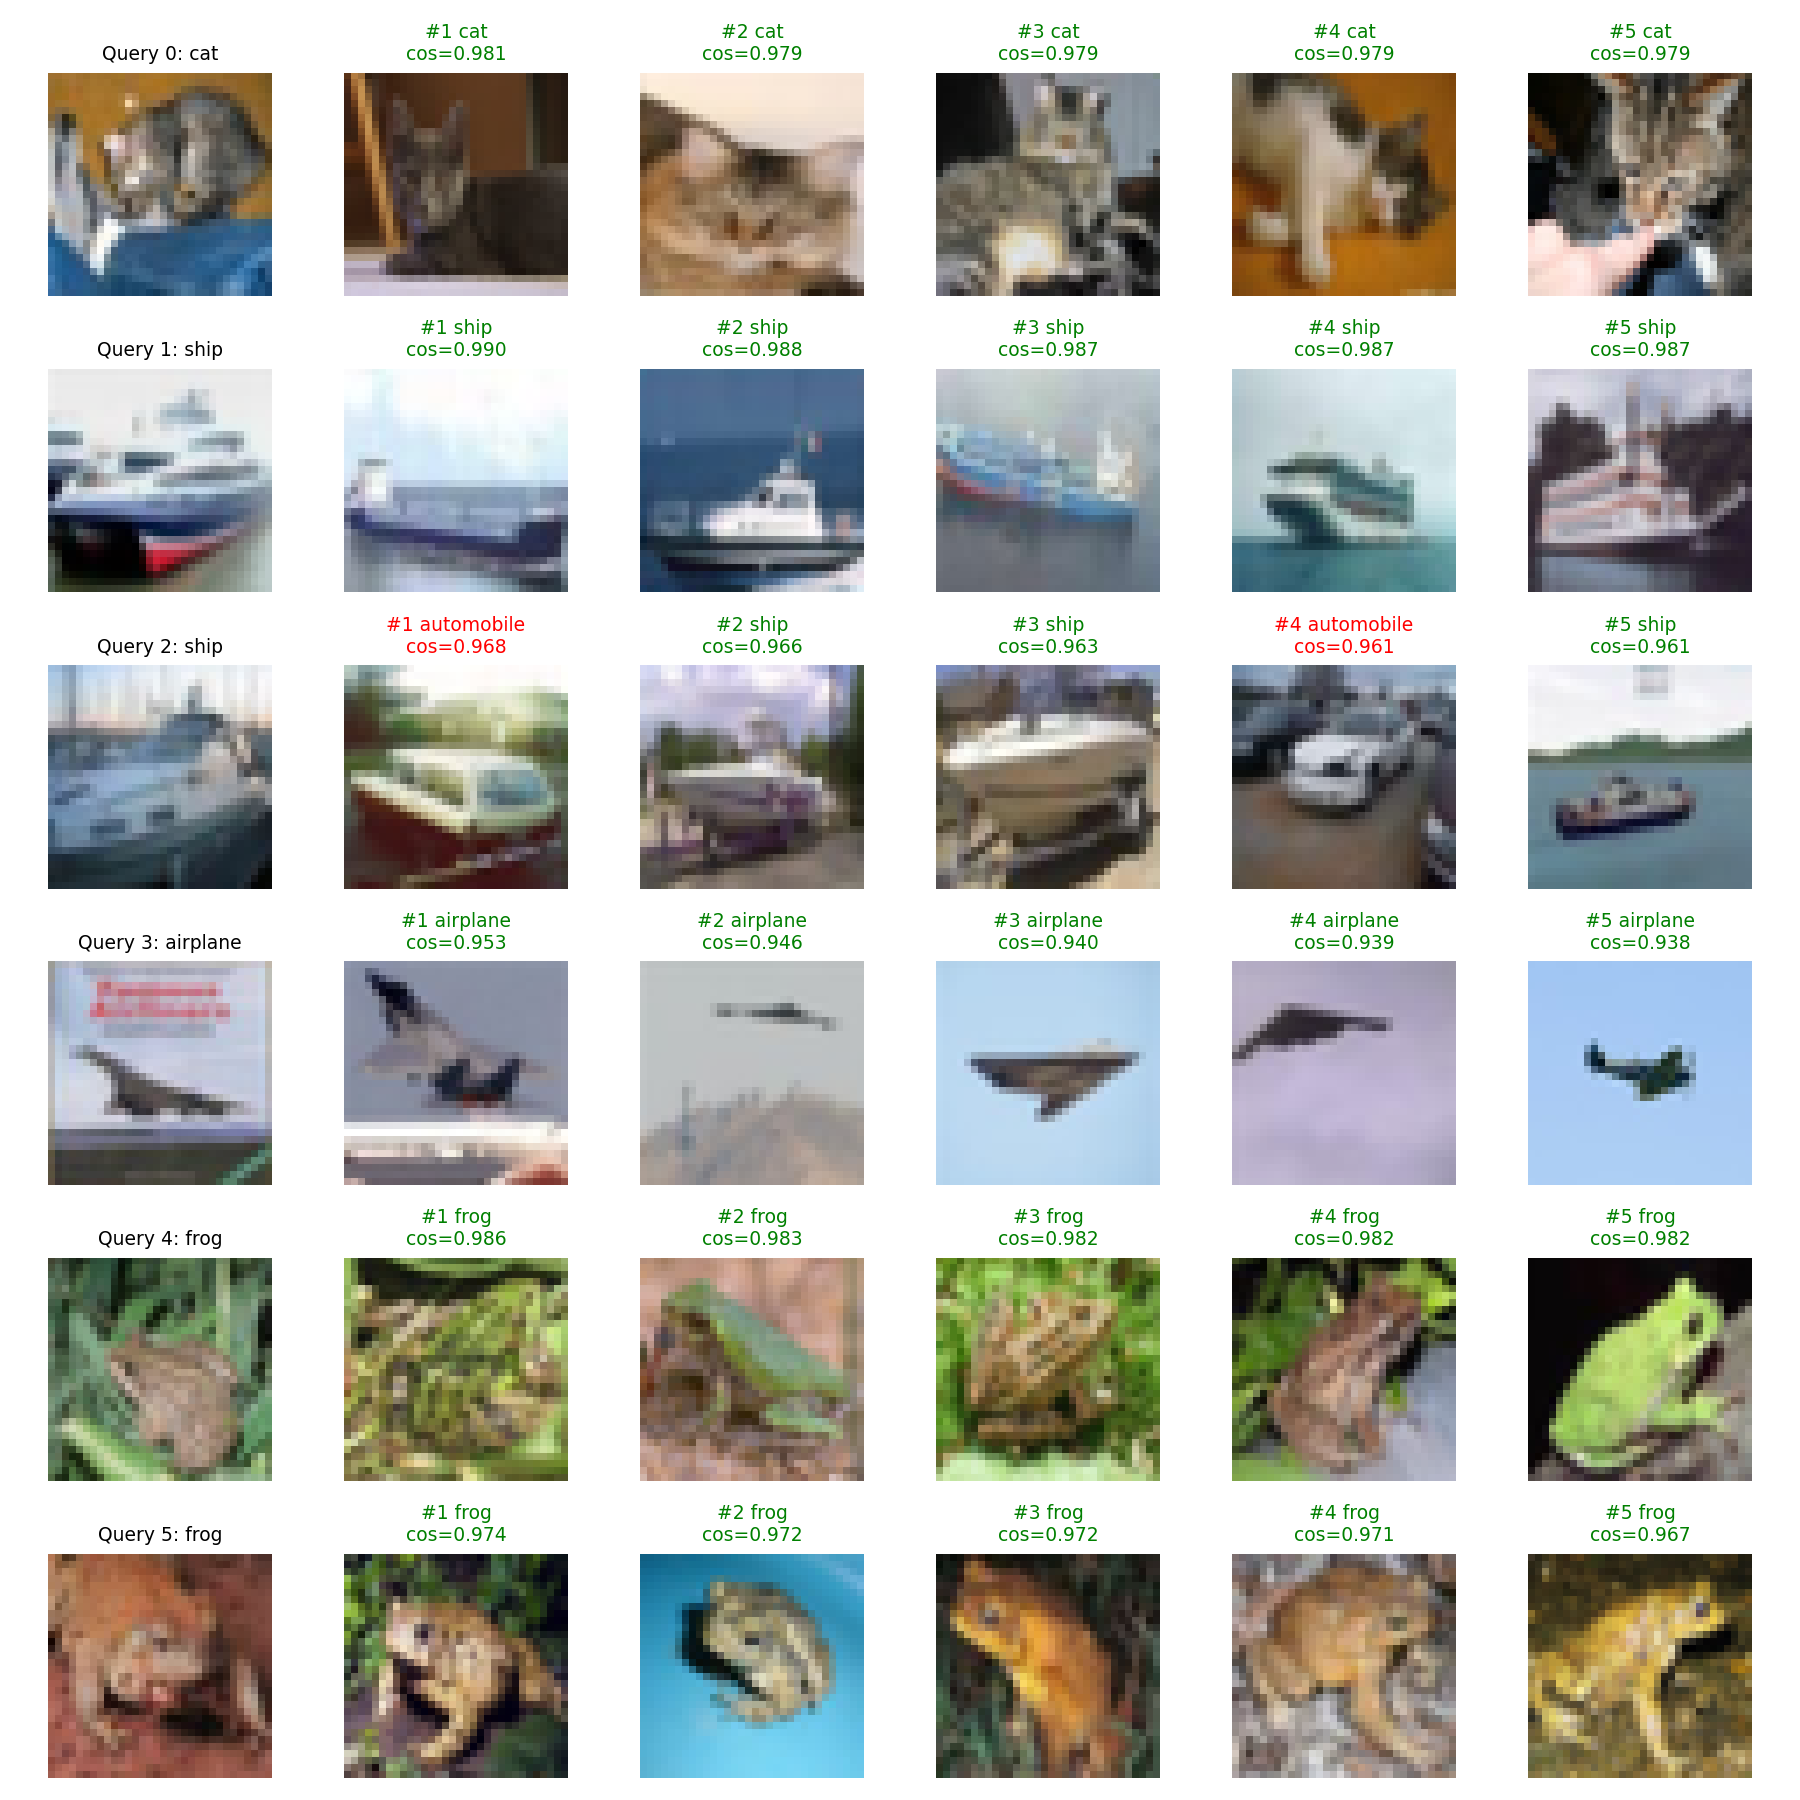

,gallery_train_id,label,cosine
0,49034,3,0.980999
1,22776,3,0.979156
2,42270,3,0.979104
3,32056,3,0.978676
4,27565,3,0.978592
5,29752,3,0.978546
6,49182,3,0.977850
7,4741,3,0.977767
8,11728,3,0.977278
9,18808,3,0.977122


In [4]:
show('retrieval_resnet.png')
show('retrieval_vit.png')
p=np.load(R/'predictions/retrieval_vit.npz')
display(pd.DataFrame({'gallery_train_id':p['gallery_ids'][0], 'label':p['neighbor_labels'][0], 'cosine':p['similarities'][0]}))

## 4. 比較檢索表現（5 分）

Hit@K 是 top-K 至少一張同類的查詢比例；P@5 是五張結果中同類比例。AP@10 的分母為 min(相關總數,10)=10，最後對 query 平均。此處 Hit@K 不能解讀為找回全部相關照片的 recall。

,model,best_epoch,trainable_parameters,train_seconds,mean_query_ms,backbone_max_abs_change,hit_at_1,hit_at_5,hit_at_10,precision_at_5,map_at_10
0,resnet,6,8460682,159.687008,4.816389,0.046070,0.8869,0.9481,0.9635,0.88156,0.854744
1,vit,4,471242,155.286048,7.052878,0.053578,0.9158,0.9633,0.9743,0.91654,0.896475


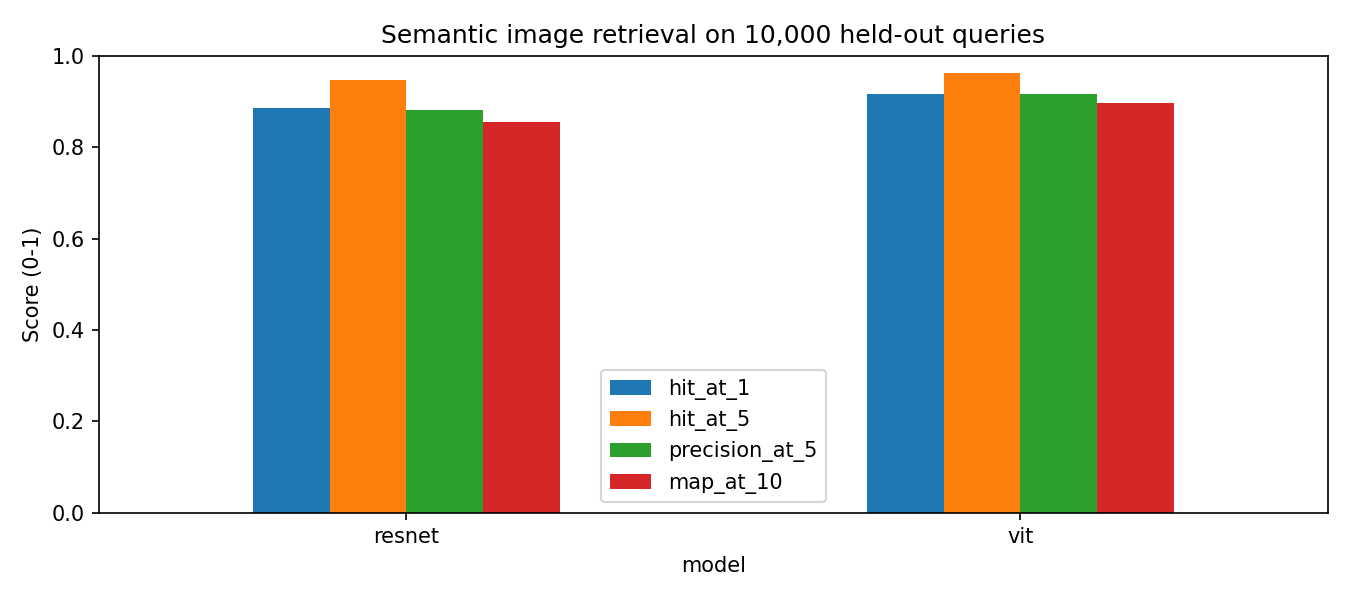

本次 mAP@10 較高：vit，0.8965


In [5]:
d=pd.read_csv(R/'retrieval_metrics.csv')
display(d)
show('retrieval_comparison.png')
best=d.loc[d.map_at_10.idxmax()]
print(f'本次 mAP@10 較高：{best.model}，{best.map_at_10:.4f}')

ViT 的 ImageNet-21k+1k 與 ResNet 的 ImageNet-1k 預訓練不同，可訓練參數量也不同；單次 seed 比較不能歸因於架構本身。查詢時間包含單圖前處理與 encoder/top-10、排除磁碟讀圖及預先建立的 gallery；暖機 3 張後量測固定 100 張，前後同步 CUDA。完整限制與數據解讀見 [報告](REPORT.md)。